# Bell-state tomography with modern pyQuil (no `qc.experiment()`)

This notebook reconstructs the density matrix of a two-qubit Bell state from measurement data. It replaces the old pyQuil 2.x workflow

```python
results = qc.experiment(bell_state_tomography)
```

which no longer works because `QuantumComputer.experiment()` was removed after pyQuil 2.x. Here every step is written out explicitly: state preparation, basis rotations, sampling, estimating Pauli expectation values, linear-inversion reconstruction, fidelity, and a projection back onto physical states.

**Contents**

1. Background: density matrices and the Pauli basis
2. The Bell state and what we expect to measure
3. Measuring in the X and Y bases
4. From bitstrings to expectation values
5. Linear inversion, and why it can give unphysical results
6. Setup and connection to the QVM
7. Running the 9 measurement settings
8. Reconstruction, fidelity and visualisation
9. Exercises

## 1. Background: density matrices and the Pauli basis

A quantum state (pure or mixed) is described by a density matrix $\rho$: a Hermitian, positive semidefinite matrix with $\operatorname{Tr}\rho = 1$. For $n$ qubits it is $2^n \times 2^n$, so two qubits need a $4\times4$ matrix with 15 real free parameters.

The single-qubit Pauli matrices together with the identity,

$$
I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\quad
X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\quad
Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\quad
Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix},
$$

form an orthogonal basis for $2\times2$ matrices under the Hilbert–Schmidt inner product $\langle A,B\rangle = \operatorname{Tr}(A^\dagger B)$, with $\operatorname{Tr}(\sigma_a\sigma_b) = 2\delta_{ab}$. Their tensor products $\sigma_a\otimes\sigma_b$ (16 of them) form a basis for $4\times4$ matrices. Any two-qubit state can therefore be written

$$
\rho \;=\; \frac{1}{4}\sum_{a,b\in\{I,X,Y,Z\}} \langle \sigma_a\otimes\sigma_b\rangle\; \sigma_a\otimes\sigma_b,
\qquad \langle \sigma_a\otimes\sigma_b\rangle = \operatorname{Tr}\!\big[\rho\,(\sigma_a\otimes\sigma_b)\big].
$$

**This is the key idea of state tomography:** if we can estimate the 16 expectation values $\langle\sigma_a\otimes\sigma_b\rangle$ from experiments, we can rebuild $\rho$. The term $\langle I\otimes I\rangle = \operatorname{Tr}\rho = 1$ is known for free, leaving 15 numbers to measure, matching the 15 free parameters.

## 2. The Bell state and what we expect to measure

The circuit `H(0); CNOT(0, 1)` applied to $|00\rangle$ produces

$$
|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt2},\qquad
\rho_{\Phi^+} = |\Phi^+\rangle\langle\Phi^+| = \frac12\begin{pmatrix}1&0&0&1\\0&0&0&0\\0&0&0&0\\1&0&0&1\end{pmatrix}.
$$

Expanding in the Pauli basis gives

$$
\rho_{\Phi^+} = \frac14\big(I\otimes I + X\otimes X - Y\otimes Y + Z\otimes Z\big),
$$

so for an ideal device we expect $\langle XX\rangle = +1$, $\langle YY\rangle = -1$, $\langle ZZ\rangle = +1$ and **all other 12 non-trivial expectation values to be 0**. In particular every single-qubit marginal ($\langle XI\rangle$, $\langle IZ\rangle$, …) is 0: each qubit on its own is maximally mixed. That is a signature of maximal entanglement.

These values are a useful sanity check for the data later on.

## 3. Measuring in the X and Y bases

Hardware (and the QVM) only measures in the computational ($Z$) basis. To measure a qubit in another Pauli basis, we first apply a rotation $U$ that maps that Pauli's eigenstates onto $|0\rangle, |1\rangle$, then measure $Z$. Formally, measuring $Z$ after $U$ is the same as measuring $U^\dagger Z U$.

| Want to measure | Rotation before `MEASURE` | Why it works |
|---|---|---|
| $Z$ | none | already the computational basis |
| $X$ | `RY(-π/2)` | $R_Y(-\tfrac{\pi}{2})\,\lvert+\rangle = \lvert0\rangle$, $\;R_Y(-\tfrac{\pi}{2})\,\lvert-\rangle = -\lvert1\rangle$ |
| $Y$ | `RX(+π/2)` | $R_X(\tfrac{\pi}{2})\,\lvert{+i}\rangle = \lvert0\rangle$, $\;R_X(\tfrac{\pi}{2})\,\lvert{-i}\rangle \propto \lvert1\rangle$ |

(`H` would also work for $X$, and `S†` followed by `H` for $Y$; the `RX`/`RY` forms are native on Rigetti hardware, so they compile more directly.)

A **measurement setting** assigns one basis to each qubit. With two qubits and three bases there are $3^2 = 9$ settings: XX, XY, XZ, YX, …, ZZ.

## 4. From bitstrings to expectation values

Each shot returns a bitstring $(b_0, b_1)$. Bit value 0 corresponds to eigenvalue $+1$ and bit 1 to eigenvalue $-1$, so the eigenvalue is $(-1)^{b}$.

- For a two-qubit operator such as $X\otimes Y$, measured in setting XY, the eigenvalue of one shot is $(-1)^{b_0 + b_1}$: the **parity** of the bitstring. Averaging over shots estimates $\langle X\otimes Y\rangle$.
- For an operator with an identity, such as $X\otimes I$, we simply **ignore** qubit 1's bit: the eigenvalue is $(-1)^{b_0}$. Any setting with $X$ on qubit 0 can be used, so the same data serves several operators. In the code below, identity positions reuse the Z-basis data for that qubit (setting XZ for $X\otimes I$, ZZ for $I\otimes I$, and so on); any choice is valid.

**Statistical error.** Each shot gives $\pm1$, so with $N$ shots the standard error of the estimate is

$$
\Delta\langle P\rangle = \sqrt{\frac{1-\langle P\rangle^2}{N}}.
$$

For $\langle P\rangle\approx 0$ and $N=2000$ this is about $0.022$. Expectation values that should be exactly $\pm1$ have (ideally) zero variance, which is why $\langle XX\rangle$, $\langle YY\rangle$, $\langle ZZ\rangle$ come out very clean on a noiseless simulator.

## 5. Linear inversion, and why it can give unphysical results

Plugging the estimated expectation values straight into the Pauli expansion from §1 is called **linear inversion**. It is fast and unbiased, but because each $\langle P\rangle$ carries shot noise, the resulting matrix is Hermitian with trace 1 yet **not guaranteed to be positive semidefinite**: it may have small negative eigenvalues, which no physical state has.

Common fixes:

- **Projection onto the nearest physical state.** Smolin, Gambetta and Smith (PRL 108, 070502, 2012) give a fast algorithm: take the eigenvalues, set negative ones to zero and redistribute the deficit evenly over the remaining ones, keeping the trace at 1. This finds the closest density matrix in 2-norm. It is implemented below.
- **Maximum-likelihood estimation (MLE).** Search over physical states for the one that makes the observed counts most likely. This is more principled but iterative and slower.

**Fidelity.** To compare the reconstruction with the ideal state we use $F = \langle\Phi^+|\rho|\Phi^+\rangle$ (valid when the target is pure). $F = 1$ is perfect; a maximally mixed two-qubit state gives $F = 0.25$.

## 6. Setup and connection to the QVM

**Requirements:** `pyquil` (v4 recommended; v3 also works), `numpy`, `matplotlib`.

To run on the QVM you need the Rigetti compiler and simulator running as servers in separate terminals:

```bash
quilc -S     # Quil compiler, port 5555
qvm  -S      # Quantum Virtual Machine, port 5000
```

Both come with the Forest SDK, or can be run as Docker images (`rigetti/quilc`, `rigetti/qvm`).

If pyQuil or the servers are unavailable, set `USE_NUMPY_FALLBACK = True` in the next cell. The notebook will then sample from an exact NumPy simulation of the same circuits, so you can still follow every step of the analysis.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

USE_NUMPY_FALLBACK = False   # True = skip pyQuil/QVM and use the NumPy sampler below

QUBITS = [0, 1]   # physical qubit indices; ro[0] holds qubit QUBITS[0], ro[1] holds QUBITS[1]
SHOTS = 2000      # shots per measurement setting (9 settings in total)
SEED = 1234       # used only by the NumPy fallback

if not USE_NUMPY_FALLBACK:
    try:
        import pyquil
        from pyquil import Program, get_qc
        from pyquil.gates import H, CNOT, RX, RY, MEASURE
        print("pyQuil version:", pyquil.__version__)
        # A 2-qubit QVM. On real hardware you would pass the QPU name instead.
        qc = get_qc("2q-qvm")
    except Exception as exc:   # ImportError, or the quilc/qvm servers are not reachable
        print(f"pyQuil unavailable ({type(exc).__name__}: {exc}); switching to the NumPy fallback.")
        USE_NUMPY_FALLBACK = True

pyQuil version: 4.20.0


## 7. Running the 9 measurement settings

`run_setting(bases)` builds one program per setting:

1. Prepare $|\Phi^+\rangle$ with `H` and `CNOT`.
2. Rotate each qubit into its measurement basis (table in §3).
3. Measure both qubits into the classical register `ro`.
4. Repeat for `SHOTS` shots, then compile and run.

It returns a `(SHOTS, 2)` array of bits. The result-access API differs between pyQuil versions, so `readout_bits` handles both.

In [2]:
# Basis-change rotations applied just before measurement (see §3).
# Each entry maps a qubit index to the gate that rotates that Pauli's eigenbasis
# onto the computational basis, or None when no rotation is needed (Z).
if not USE_NUMPY_FALLBACK:
    ROTATION = {
        "X": lambda q: RY(-np.pi / 2, q),
        "Y": lambda q: RX(np.pi / 2, q),
        "Z": lambda q: None,
    }


def readout_bits(result, name="ro"):
    """Return the measured bits as a (shots, n_bits) array for pyQuil 3 or 4."""
    if hasattr(result, "get_register_map"):      # pyQuil 4
        return np.asarray(result.get_register_map()[name])
    return np.asarray(result.readout_data.get(name))   # pyQuil 3


def run_setting_pyquil(bases):
    """Prepare |Phi+>, rotate into `bases` (e.g. ('X', 'Y')), measure SHOTS times."""
    p = Program()
    ro = p.declare("ro", "BIT", len(QUBITS))        # classical register for results

    # 1. State preparation: |00> -> (|00> + |11>)/sqrt(2)
    p += H(QUBITS[0])
    p += CNOT(QUBITS[0], QUBITS[1])

    # 2. Basis change: one rotation per qubit (none for Z)
    for basis, q in zip(bases, QUBITS):
        gate = ROTATION[basis](q)
        if gate is not None:
            p += gate

    # 3. Computational-basis measurement: qubit QUBITS[i] -> ro[i]
    for i, q in enumerate(QUBITS):
        p += MEASURE(q, ro[i])

    # 4. Repeat the whole program SHOTS times, compile to native gates, execute
    p = p.wrap_in_numshots_loop(SHOTS)
    executable = qc.compile(p)
    return readout_bits(qc.run(executable))

### NumPy fallback sampler

This exact state-vector simulation mirrors `run_setting_pyquil` gate for gate. It is only used when pyQuil is not available, and it doubles as an independent check of the rotation conventions. Qubit 0 is the left (most significant) factor in every tensor product, matching `ro[0]`.

In [3]:
def rx(theta):
    """Single-qubit RX(theta) = exp(-i theta X / 2), same convention as Quil."""
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -1j * s], [-1j * s, c]])


def ry(theta):
    """Single-qubit RY(theta) = exp(-i theta Y / 2), same convention as Quil."""
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]])


NP_ROTATION = {"X": ry(-np.pi / 2), "Y": rx(np.pi / 2), "Z": np.eye(2)}
_rng = np.random.default_rng(SEED)


def run_setting_numpy(bases):
    """Sample SHOTS bitstrings from the ideal circuit, as a (SHOTS, 2) bit array."""
    psi = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)          # |Phi+>
    psi = np.kron(NP_ROTATION[bases[0]], NP_ROTATION[bases[1]]) @ psi  # basis change
    probs = np.abs(psi) ** 2
    outcomes = _rng.choice(4, size=SHOTS, p=probs / probs.sum())       # index b0*2 + b1
    return np.stack([outcomes // 2, outcomes % 2], axis=1)


run_setting = run_setting_numpy if USE_NUMPY_FALLBACK else run_setting_pyquil
print("Using", run_setting.__name__)

Using run_setting_pyquil


In [4]:
%%time
# Run all 3^2 = 9 settings. Keys are tuples such as ('X', 'Y') = X on qubit 0, Y on qubit 1.
SETTINGS = list(itertools.product("XYZ", repeat=len(QUBITS)))
data = {setting: run_setting(setting) for setting in SETTINGS}

for setting, bits in data.items():
    # Quick look at the raw data: how often each bitstring occurred
    counts = {f"{a}{b}": int(np.sum((bits[:, 0] == a) & (bits[:, 1] == b))) for a in (0, 1) for b in (0, 1)}
    print("".join(setting), counts)

XX {'00': 1009, '01': 0, '10': 0, '11': 991}
XY {'00': 511, '01': 524, '10': 485, '11': 480}
XZ {'00': 526, '01': 502, '10': 512, '11': 460}
YX {'00': 497, '01': 500, '10': 498, '11': 505}
YY {'00': 0, '01': 977, '10': 1023, '11': 0}
YZ {'00': 464, '01': 476, '10': 504, '11': 556}
ZX {'00': 531, '01': 484, '10': 470, '11': 515}
ZY {'00': 492, '01': 494, '10': 503, '11': 511}
ZZ {'00': 1023, '01': 0, '10': 0, '11': 977}
CPU times: user 33.3 ms, sys: 12 ms, total: 45.3 ms
Wall time: 1.41 s


In the raw counts you should see that ZZ gives only `00` and `11` (perfect correlation), XX also gives only `00`/`11`, and YY gives only `01`/`10` (perfect anti-correlation, since $\langle YY\rangle = -1$). Mixed settings such as XZ are roughly uniform.

## 8. Reconstruction, fidelity and visualisation

### 8.1 Estimate all 16 Pauli expectation values

In [5]:
PAULI = {
    "I": np.eye(2, dtype=complex),
    "X": np.array([[0, 1], [1, 0]], dtype=complex),
    "Y": np.array([[0, -1j], [1j, 0]], dtype=complex),
    "Z": np.array([[1, 0], [0, -1]], dtype=complex),
}


def estimate_expectation(label):
    """Estimate <label> (e.g. 'XI') and its standard error from the measured data (§4)."""
    # Choose a setting that measures every non-identity factor; identity slots use Z data.
    setting = tuple(p if p != "I" else "Z" for p in label)
    bits = data[setting]
    mask = np.array([p != "I" for p in label])     # which qubits contribute to the parity
    if not mask.any():                             # <I I> = Tr(rho) = 1 exactly
        return 1.0, 0.0
    eigenvalues = (-1.0) ** bits[:, mask].sum(axis=1)   # +1 for even parity, -1 for odd
    mean = eigenvalues.mean()
    stderr = np.sqrt(max(1 - mean**2, 0.0) / len(eigenvalues))
    return mean, stderr


LABELS = ["".join(p) for p in itertools.product("IXYZ", repeat=len(QUBITS))]
expectations = {lab: estimate_expectation(lab) for lab in LABELS}

for lab in LABELS:
    mean, err = expectations[lab]
    print(f"<{lab}> = {mean:+.3f} ± {err:.3f}")

<II> = +1.000 ± 0.000
<IX> = +0.001 ± 0.022
<IY> = -0.005 ± 0.022
<IZ> = +0.023 ± 0.022
<XI> = +0.028 ± 0.022
<XX> = +1.000 ± 0.000
<XY> = -0.009 ± 0.022
<XZ> = -0.014 ± 0.022
<YI> = -0.060 ± 0.022
<YX> = +0.002 ± 0.022
<YY> = -1.000 ± 0.000
<YZ> = +0.020 ± 0.022
<ZI> = +0.023 ± 0.022
<ZX> = +0.046 ± 0.022
<ZY> = +0.003 ± 0.022
<ZZ> = +1.000 ± 0.000


### 8.2 Linear inversion

$\rho = \tfrac14 \sum_{ab} \langle\sigma_a\otimes\sigma_b\rangle\,\sigma_a\otimes\sigma_b$ (§1).

In [6]:
def pauli_operator(label):
    """Tensor product of single-qubit Paulis, qubit 0 leftmost: 'XY' -> X ⊗ Y."""
    op = np.array([[1.0 + 0j]])
    for p in label:
        op = np.kron(op, PAULI[p])
    return op


dim = 2 ** len(QUBITS)
rho_lin = sum(expectations[lab][0] * pauli_operator(lab) for lab in LABELS) / dim

np.set_printoptions(precision=3, suppress=True)
print("Linear-inversion estimate of rho:\n", rho_lin)
print("trace          :", np.trace(rho_lin).real)
print("Hermitian?     :", np.allclose(rho_lin, rho_lin.conj().T))
print("eigenvalues    :", np.linalg.eigvalsh(rho_lin))

Linear-inversion estimate of rho:
 [[ 0.511+0.j     0.012+0.001j  0.004+0.01j   0.5  +0.002j]
 [ 0.012-0.001j  0.   +0.j     0.   -0.003j  0.011+0.02j ]
 [ 0.004-0.01j   0.   +0.003j -0.   +0.j    -0.011+0.002j]
 [ 0.5  -0.002j  0.011-0.02j  -0.011-0.002j  0.488+0.j   ]]
trace          : 0.9999999999999999
Hermitian?     : True
eigenvalues    : [-0.019 -0.002  0.021  1.001]


### 8.3 Project onto the nearest physical state (Smolin–Gambetta–Smith)

If any eigenvalue above is negative, the estimate is unphysical. The algorithm below fixes that while changing $\rho$ as little as possible.

In [7]:
def project_to_physical(rho):
    """Closest density matrix to `rho` in 2-norm (Smolin, Gambetta, Smith, PRL 108, 070502).

    Works from the smallest eigenvalue upward: while an eigenvalue (plus the share of
    accumulated negative weight it must absorb) is negative, set it to zero and carry
    its weight forward; spread the remaining deficit evenly over the surviving eigenvalues.
    """
    rho = (rho + rho.conj().T) / 2                   # enforce exact Hermiticity
    rho = rho / np.trace(rho).real                   # enforce unit trace
    evals, evecs = np.linalg.eigh(rho)               # ascending order
    evals = evals.copy()
    d = len(evals)
    accumulated = 0.0
    i = 0
    while i < d and evals[i] + accumulated / (d - i) < 0:
        accumulated += evals[i]                      # negative weight to redistribute
        evals[i] = 0.0
        i += 1
    evals[i:] += accumulated / (d - i)               # share the deficit among the rest
    return (evecs * evals) @ evecs.conj().T


rho_phys = project_to_physical(rho_lin)
print("eigenvalues after projection:", np.linalg.eigvalsh(rho_phys))

eigenvalues after projection: [-0.    0.    0.01  0.99]


### 8.4 Fidelity and purity

In [8]:
phi_plus = np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)
rho_ideal = np.outer(phi_plus, phi_plus.conj())

for name, rho in [("linear inversion", rho_lin), ("projected", rho_phys)]:
    fidelity = np.real(phi_plus.conj() @ rho @ phi_plus)   # <Phi+| rho |Phi+>
    purity = np.real(np.trace(rho @ rho))                 # 1 for a pure state, 1/4 fully mixed
    print(f"{name:17s}  fidelity = {fidelity:.4f}   purity = {purity:.4f}")

linear inversion   fidelity = 1.0000   purity = 1.0021
projected          fidelity = 0.9893   purity = 0.9800


**Reading the result.** With a noiseless simulator, the linear-inversion estimate can report a fidelity at or slightly above 1 and a purity above 1. Neither is possible for a real state; both are symptoms of the negative eigenvalues seen in §8.2. After projection the numbers are physical (purity ≤ 1), and the fidelity drops slightly because the shot noise in the 12 "should be zero" expectation values is now treated as genuine mixedness. On a noisy device or the noisy QVM, the drop in fidelity from noise is usually much larger than this effect.

### 8.5 Visualisation

Left: the 15 measured Pauli expectation values with error bars against the ideal values. Right: the real part of the reconstructed density matrix. The imaginary part should be close to zero for $|\Phi^+\rangle$.

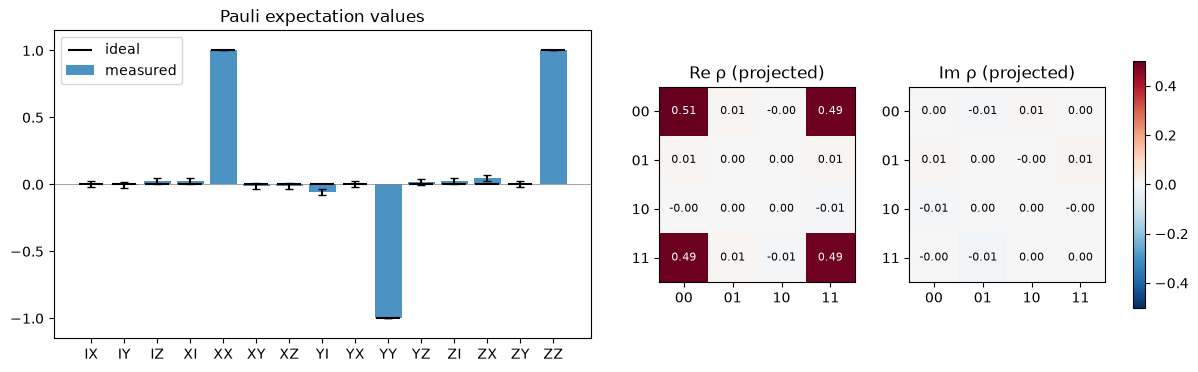

In [9]:
labels = LABELS[1:]                                   # skip II (always 1)
means = np.array([expectations[l][0] for l in labels])
errs = np.array([expectations[l][1] for l in labels])
ideal = np.array([np.real(np.trace(rho_ideal @ pauli_operator(l))) for l in labels])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2.2, 1, 1]})

x = np.arange(len(labels))
axes[0].bar(x, means, yerr=errs, capsize=3, label="measured", alpha=0.8)
axes[0].scatter(x, ideal, color="k", marker="_", s=300, label="ideal", zorder=3)
axes[0].set_xticks(x, labels)
axes[0].set_ylim(-1.15, 1.15)
axes[0].axhline(0, color="grey", lw=0.5)
axes[0].set_title("Pauli expectation values")
axes[0].legend()

basis = ["00", "01", "10", "11"]
for ax, part, title in [(axes[1], rho_phys.real, "Re ρ (projected)"),
                        (axes[2], rho_phys.imag, "Im ρ (projected)")]:
    im = ax.imshow(part, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(4), basis)
    ax.set_yticks(range(4), basis)
    for (r, c), v in np.ndenumerate(part):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.3 else "black")   # keep labels readable
    ax.set_title(title)
fig.colorbar(im, ax=axes[1:], shrink=0.8)
plt.show()

## 9. Exercises

1. **Shot noise.** Rerun with `SHOTS = 100` and `SHOTS = 10000`. How do the error bars and the infidelity $1-F$ scale with $N$? (Expect roughly $1/\sqrt N$ for the error bars.)
2. **Another Bell state.** Add `X(QUBITS[1])` after the CNOT to prepare $|\Psi^+\rangle = (|01\rangle+|10\rangle)/\sqrt2$. Predict the signs of $\langle XX\rangle$, $\langle YY\rangle$, $\langle ZZ\rangle$ first, then check. Remember to update `phi_plus` for the fidelity.
3. **Noise.** On the QVM, add depolarising noise, for example with `qc = get_qc("2q-qvm", noisy=True)` or `pyquil.noise.add_decoherence_noise`. How do fidelity and purity drop? Which expectation values shrink?
4. **Fewer settings.** The 9 settings measure each two-qubit Pauli once, but the single-qubit terms (XI, IZ, …) can be estimated from three settings each. Average over all of them and check whether the error bars shrink.
5. **Basis-rotation bug hunt.** Change the X rotation to `RY(+π/2)`. Which expectation values flip sign, and why does the fidelity still look reasonable for some states but not others?

### References

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, §8.4.2 (state tomography).
- J. A. Smolin, J. M. Gambetta and G. Smith, "Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise", *Phys. Rev. Lett.* **108**, 070502 (2012).
- pyQuil documentation: https://pyquil-docs.rigetti.com